###                  AIR VEHICLE DESIGN
###                   GROUP ASSINGMENT 1
###                       GROUP 5
###                     14/02/2024

In [60]:
# importing needed function
from matplotlib import pyplot as plt
from math import exp
import os

In [61]:
# creating file for saving data
try:
    os.remove("data_range.txt")
    os.remove("data_payload.txt")
    os.remove("data_weight.txt")
except:
    pass

In [62]:
# taking in data
R = eval(input("Enter your cruise range(start,end,step): "))
W_payload = eval(input("Enter your payload(start,end,step): "))

# Displaying inputs
print("Range: ", R)
print("Payload: ", W_payload)

Range:  9114000
Payload:  range(10000, 30000, 500)


In [63]:
# adjusting for single inputs
if type(R) in [int,float]: R = [R]
if type(W_payload) in [int,float]: W_payload = [W_payload]

In [64]:
#setting project constants and constant
C_cruise = 0.0001389; V=569; L_D_cruise =13.9; L_D_loiter =16; E_l1 = 10800; C_loiter = 0.0001111; E_l2 =1200; 
W1_W0 = 0.97; W2_W1 = 0.985; W7_W6 = 0.995; W_crew = 800

In [65]:
# cruise creating function
def cruise_func(R, C, L_D, V): 
    return exp((-R*C)/(L_D*V))

#creating loiter function
def loiter_func(E, C, L_D):
    return exp((-E*C)/L_D)

In [66]:
# writing loop for range
for r in R:
    W7_W0 = W1_W0 * W2_W1 * cruise_func(r, C_cruise, L_D_cruise, V)* loiter_func(E_l1, C_loiter, L_D_loiter)* cruise_func(r, C_cruise, L_D_cruise, V)* loiter_func(E_l2, C_loiter, L_D_loiter)* W7_W6


    # looping payload
    for payload in W_payload:


        # Guess the intial weight value
        W0_guess = 4 * (payload + W_crew)
        

        while True:


            #calculating W0
            W0= (W_crew + payload)/ (1 - (1.06*(1-W7_W0)) - (0.93*(W0_guess**-0.07) ))
            

            # writing error 
            err = abs(W0 - W0_guess)


            if err <= 10**-4:


            # saving data in CSV file, r, payload, W0
                with open("data_range.txt", "+a") as fh_range:
                    fh_range.write(str(r)+"\n")

                with open("data_payload.txt","+a") as fh_payload:
                    fh_payload.write(str(payload)+"\n")

                with open("data_weight.txt", "+a") as fh_W0:
                    fh_W0.write(str(W0)+"\n")
                
        
                break
            else:
                W0_guess = (W0 + W0_guess)/2

In [67]:
#retieving the data into x, y, and z
with open("data_range.txt", "r") as fh_range:
    x = list(map(int, fh_range.readlines()))

with open ("data_payload.txt","r") as fh_payload:
    y= list(map(int, fh_payload.readlines()))

with open("data_weight.txt", "r") as fh_W0:
    z= list(map(float, fh_W0.readlines()))


# Displaying your output
print("Range   Payload    Weights")
for i in range(len(z)):
    print(f"{x[i]:2d} {y[i]:2d} {z[i]:2f}")

Range   Payload    Weights
9114000 10000 59258.383980
9114000 10500 61606.191095
9114000 11000 63942.327870
9114000 11500 66267.412656
9114000 12000 68582.006915
9114000 12500 70886.622474
9114000 13000 73181.727660
9114000 13500 75467.752404
9114000 14000 77745.092657
9114000 14500 80014.114132
9114000 15000 82275.155536
9114000 15500 84528.531360
9114000 16000 86774.534304
9114000 16500 89013.437394
9114000 17000 91245.495842
9114000 17500 93470.948677
9114000 18000 95690.020188
9114000 18500 97902.921204
9114000 19000 100109.850234
9114000 19500 102310.994478
9114000 20000 104506.530741
9114000 20500 106696.626242
9114000 21000 108881.439355
9114000 21500 111061.120263
9114000 22000 113235.811563
9114000 22500 115405.648806
9114000 23000 117570.760991
9114000 23500 119731.271012
9114000 24000 121887.296068
9114000 24500 124038.948038
9114000 25000 126186.333825
9114000 25500 128329.555666
9114000 26000 130468.711426
9114000 26500 132603.894859
9114000 27000 134735.195850
9114000 275

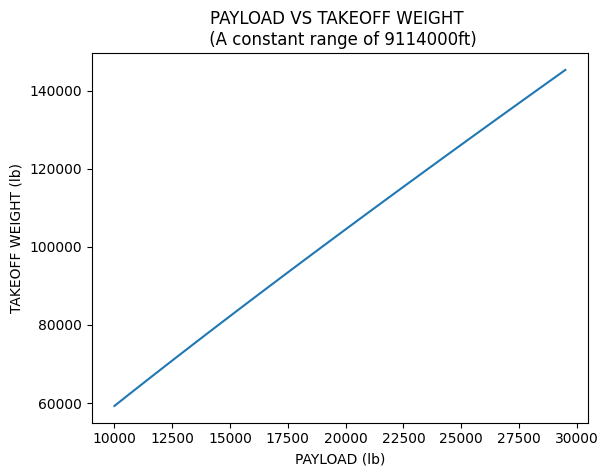

In [68]:
%matplotlib inline
# What to plot
if len(x)+ len(y) == 2:
    print(z)
elif x[0]== x[-1]:
    plt.plot(y,z)
    plt.title(f"PAYLOAD VS TAKEOFF WEIGHT \n (A constant range of {x[0]}ft)")
    plt.xlabel("PAYLOAD (lb)")
    plt.ylabel("TAKEOFF WEIGHT (lb)")
elif y[0]==y[-1]:
    plt.plot(x,z)
    plt.title(f"RANGE VS TAKEOFF WEIGHT \n (A constant payload of {y[0]}-lb)")
    plt.xlabel("AIRCRAFT RANGE (ft)")
    plt.ylabel("TAKEOFF WEIGHT (lb)")

#showing plot
plt.show()

GROUP 5 MEMBERS
- ACHEAMPONG RANDY
- MOHAMMED SALIFU ZAKARI
- OWUSU SAMUEL KYEI 
- OCANSEY JASON YAW AKROFI
- APPIA-KUBI APPIA NIMO OWURAKU
- ARMAH SAMUEL NYAMEKYE
- AZAMETI EMMANUEL
- OTOO JONATHAN NII-NORTEY
- YEBOAH AMA SERWAA
- AMARQUAYE EPHRAIM CHRISTIAN NII AMARKAI